<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [scikit-bio](https://github.com/Query-farm/vgi-scikit-bio)

Bioinformatics functions for sequence analysis, alignment, microbial diversity, ordination and phylogenetic trees.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-scikit-bio/blob/main/notebooks/04_coordinates_do_not_recover_totals.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-scikit-bio/blob/main/notebooks/README.md)


## 04 · Coordinates do not recover totals

Can changing a log-ratio reference change a chart without changing the composition it represents? We transform four positive synthetic compositions using CLR, ILR and ALR, invert each through the worker, and separately measure which feature ratios vary across the inputs.

The feature names **a, b and c are arbitrary**. All twelve entries are strictly positive; this notebook neither imputes zeros nor interprets missing observations. `REFERENCE_FEATURE` is **"a"** by default and the experiment uses **"c"**. The inputs stay fixed.

In [1]:
REFERENCE_FEATURE = "a"  # one of a, b, c; experiment: c

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.29":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.29"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme

if REFERENCE_FEATURE not in ("a", "b", "c"):
    raise ValueError("REFERENCE_FEATURE must be a, b or c.")
REFERENCE_INDEX = ["a", "b", "c"].index(REFERENCE_FEATURE)
theme()
session = connect(globals())
Path("artifacts").mkdir(exist_ok=True)
SOURCE = "Source: authored synthetic inputs · actual vgi-scikit-bio v0.3.0 worker · no biological inference"

### Connect to the released scientific worker

The short literal Git-tag launcher uses **v0.3.0** in a separate Python 3.13 process. Its release owns scientific and protocol dependencies; no source checkout or transitive overrides are needed. The notebook kernel uses the shared base package. First use downloads the worker and VGI; all analytical inputs below are synthetic and local. Shared connection setup creates an empty temporary SQL secret directory and disables persistent secrets.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'skbio' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-scikit-bio@v0.3.0 vgi-scikit-bio');

,Success


### Close positive parts and keep their original totals separately

Closure divides each row by its total. Every transform receives the same complete, ordered long table. Feature order is explicitly **a, b, c**. The inverse functions return numeric part indices, which SQL maps back to that same order rather than guessing names from output positions.

In [5]:
%%sql
CREATE TABLE parts AS SELECT * FROM (VALUES
 ('s1','a',1.0),('s1','b',2.0),('s1','c',4.0),
 ('s2','a',2.0),('s2','b',4.0),('s2','c',1.0),
 ('s3','a',3.0),('s3','b',6.0),('s3','c',9.0),
 ('s4','a',4.0),('s4','b',8.0),('s4','c',2.0)
) AS t(sample_id,feature_id,value);
CREATE TABLE feature_order AS SELECT * FROM (VALUES (1,'a'),(2,'b'),(3,'c')) AS t(feature,feature_id);
CREATE TABLE closed AS SELECT * FROM skbio.stats.closure((SELECT * FROM parts ORDER BY sample_id,feature_id));
SELECT p.sample_id,sum(p.value) AS original_total,
 sum(c.proportion) AS closed_total FROM parts p JOIN closed c USING(sample_id,feature_id)
GROUP BY p.sample_id ORDER BY p.sample_id;

,sample_id,original_total,closed_total
0,s1,7.0,1.0
1,s2,7.0,1.0
2,s3,18.0,1.0
3,s4,14.0,1.0


### Three coordinate systems encode the same composition

CLR is `ln(part / geometric mean)` and has three coordinates summing to zero. ILR uses the worker's default orthonormal basis and has two coordinates; these component numbers are not feature identities. ALR has two coordinates relative to the chosen part. A zero ALR coordinate means equal parts, while a zero CLR coordinate means equality with that sample's geometric mean.

The ALR reference index is zero-based, derived from the visible `REFERENCE_FEATURE` parameter and the stated feature order. We verify the coordinate formulas in SQL and use matching reference indices on inversion.

In [6]:
%%sql
CREATE TABLE clr_coordinates AS SELECT * FROM skbio.stats.clr((SELECT * FROM parts ORDER BY sample_id,feature_id));
CREATE TABLE ilr_coordinates AS SELECT * FROM skbio.stats.ilr((SELECT * FROM parts ORDER BY sample_id,feature_id));
CREATE TABLE alr_coordinates AS SELECT * FROM skbio.stats.alr((SELECT * FROM parts ORDER BY sample_id,feature_id),ref_idx := {{REFERENCE_INDEX}});
CREATE TABLE coordinates AS
SELECT 'CLR' AS method,sample_id,feature_id AS coordinate,clr AS value FROM clr_coordinates
UNION ALL SELECT 'ILR',sample_id,'component '||component,value FROM ilr_coordinates
UNION ALL SELECT 'ALR',a.sample_id,f.feature_id||' / {{REFERENCE_FEATURE}}',a.value
FROM alr_coordinates a JOIN (
 SELECT feature_id,row_number() OVER(ORDER BY feature) AS component
 FROM feature_order WHERE feature_id<>'{{REFERENCE_FEATURE}}'
) f USING(component);
SELECT * FROM coordinates ORDER BY method,sample_id,coordinate;

,method,sample_id,coordinate,value
0,ALR,s1,b / a,0.693147
1,ALR,s1,c / a,1.386294
2,ALR,s2,b / a,0.693147
3,ALR,s2,c / a,-0.693147
4,ALR,s3,b / a,0.693147
5,ALR,s3,c / a,1.098612
6,ALR,s4,b / a,0.693147
7,ALR,s4,c / a,-0.693147
8,CLR,s1,a,-0.693147
9,CLR,s1,b,0.000000


In [7]:
%%sql coords <<
SELECT * FROM coordinates ORDER BY method,sample_id,coordinate;

The **28 returned coordinates** encode four compositions: 12 CLR values, eight ILR values and eight ALR values. The selected ALR denominator is **a**. Coordinates use natural logarithms of dimensionless ratios; their sign is meaningful only with the named reference or basis.

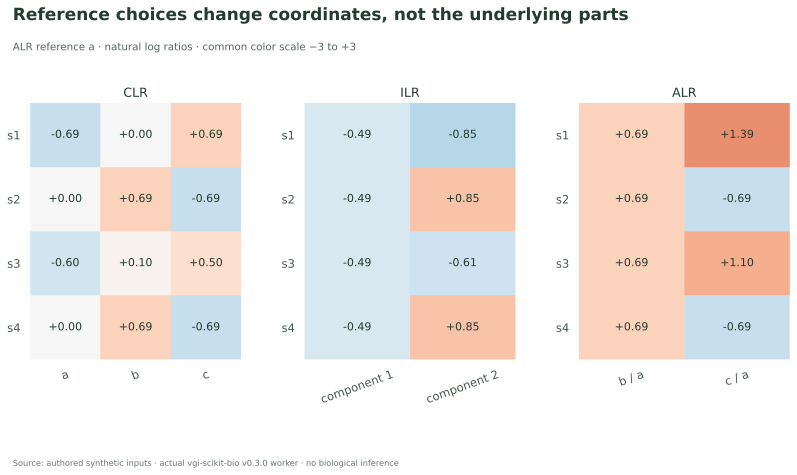

In [8]:
prose(
    f"The **{len(coords)} returned coordinates** encode four compositions: 12 CLR values, eight ILR values and eight ALR values. The selected ALR denominator is **{REFERENCE_FEATURE}**. Coordinates use natural logarithms of dimensionless ratios; their sign is meaningful only with the named reference or basis."
)
fig, axes = plt.subplots(1, 3, figsize=(12, 7))
for ax, method in zip(axes, ["CLR", "ILR", "ALR"], strict=True):
    matrix = coords[coords.method == method].pivot(
        index="sample_id", columns="coordinate", values="value"
    )
    ax.imshow(matrix, vmin=-3, vmax=3, cmap="RdBu_r", aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=20)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(method)
    for i in range(len(matrix)):
        for j in range(len(matrix.columns)):
            ax.text(j, i, f"{matrix.iloc[i, j]:+.2f}", ha="center", va="center", color="#20382B")
finish(
    fig,
    "Reference choices change coordinates, not the underlying parts",
    f"ALR reference {REFERENCE_FEATURE} · natural log ratios · common color scale −3 to +3",
    SOURCE,
    name=f"coordinates-{REFERENCE_FEATURE}",
)

### Invert each representation and reconcile every part

The inverse transforms recover proportions, not the original totals 7, 7, 18 and 14. SQL joins every numeric output index back to a feature and compares all twelve reconstructed proportions with closure. A small maximum error is evidence for these complete round trips; it does not establish recovery of information that closure discarded.

In [9]:
%%sql
CREATE TABLE inverse_parts AS
SELECT 'CLR' AS method,* FROM skbio.stats.clr_inv(
 (SELECT sample_id,feature_id,clr FROM clr_coordinates ORDER BY sample_id,feature_id))
UNION ALL SELECT 'ILR',* FROM skbio.stats.ilr_inv(
 (SELECT sample_id,component,value FROM ilr_coordinates ORDER BY sample_id,component))
UNION ALL SELECT 'ALR',* FROM skbio.stats.alr_inv(
 (SELECT sample_id,component,value FROM alr_coordinates ORDER BY sample_id,component),ref_idx := {{REFERENCE_INDEX}});
CREATE TABLE roundtrip AS SELECT i.method,i.sample_id,f.feature_id,i.value AS recovered,c.proportion,
 abs(i.value-c.proportion) AS error
FROM inverse_parts i JOIN feature_order f USING(feature) JOIN closed c USING(sample_id,feature_id);
SELECT method,count(*) AS compared_parts,max(error) AS maximum_absolute_error,
 min(recovered) AS smallest_recovered_proportion
FROM roundtrip GROUP BY method ORDER BY method;

,method,compared_parts,maximum_absolute_error,smallest_recovered_proportion
0,ALR,12,2.775558e-17,0.142857
1,CLR,12,2.775558e-17,0.142857
2,ILR,12,2.775558e-17,0.142857


Each method returns twelve proportions. All are compared against the same closed input, including both samples with identical composition but different totals (`s2` and `s4`). Feature naming is a separate bookkeeping step, and a round trip requires the same ALR reference and ILR basis.

### Feature log-ratio variance answers a different question

`pairwise_vlr` compares **features across samples**, not samples against each other. Its default sample-variance denominator is n−1. Here b is exactly twice a in every row, so `ln(a/b)` is constant and its variance should be zero. Ratios involving c vary. SQL independently reconstructs `var_samp(ln(x/y))` for every pair.

These four authored rows are not biological replicates. The variance is a descriptive property of the construction, not an inferential significance test. See the [scikit-bio pairwise VLR definition](https://scikit.bio/docs/latest/generated/skbio.stats.composition.pairwise_vlr.html).

In [10]:
%%sql
CREATE TABLE vlr_worker AS SELECT * FROM skbio.stats.pairwise_vlr((SELECT * FROM parts ORDER BY sample_id,feature_id));
CREATE TABLE vlr_sql AS SELECT a.feature_id AS feature_1,b.feature_id AS feature_2,
 var_samp(ln(a.value/b.value)) AS reconstructed
FROM parts a JOIN parts b USING(sample_id) GROUP BY a.feature_id,b.feature_id;
SELECT w.feature_1,w.feature_2,w.vlr,s.reconstructed,abs(w.vlr-s.reconstructed) AS error
FROM vlr_worker w JOIN vlr_sql s USING(feature_1,feature_2)
WHERE feature_1<feature_2 ORDER BY feature_1,feature_2;

,feature_1,feature_2,vlr,reconstructed,error
0,a,b,0.000000,0.000000,0.0
1,a,c,1.262643,1.262643,0.0
2,b,c,1.262643,1.262643,0.0


In [11]:
%%sql variances <<
SELECT * FROM vlr_worker WHERE feature_1<feature_2 ORDER BY feature_1,feature_2;

In [12]:
%%sql checks <<
SELECT 'positive_complete_unique_input' AS check_name,count(*)=12 AND count(DISTINCT(sample_id,feature_id))=12 AND bool_and(value>0) AS passed FROM parts
UNION ALL SELECT 'closure_formula',bool_and(abs(proportion-value/total)<1e-12) FROM closed JOIN (SELECT *,sum(value) OVER(PARTITION BY sample_id) AS total FROM parts) USING(sample_id,feature_id)
UNION ALL SELECT 'clr_sum_zero',bool_and(abs(total)<1e-12) FROM (SELECT sample_id,sum(clr) AS total FROM clr_coordinates GROUP BY sample_id)
UNION ALL SELECT 'clr_formula',bool_and(abs(clr-expected)<1e-12) FROM clr_coordinates JOIN (SELECT sample_id,feature_id,ln(value)-avg(ln(value)) OVER(PARTITION BY sample_id) AS expected FROM parts) USING(sample_id,feature_id)
UNION ALL SELECT 'ilr_norm_preserved',bool_and(abs(a.n-b.n)<1e-12) FROM (SELECT sample_id,sum(clr*clr) AS n FROM clr_coordinates GROUP BY sample_id) a JOIN (SELECT sample_id,sum(value*value) AS n FROM ilr_coordinates GROUP BY sample_id) b USING(sample_id)
UNION ALL SELECT 'all_roundtrips',count(*)=36 AND bool_and(error<1e-12 AND recovered>0) FROM roundtrip
UNION ALL SELECT 'alr_formula',bool_and(abs(c.value-ln(p.value/r.value))<1e-12) FROM coordinates c JOIN parts p ON c.sample_id=p.sample_id AND split_part(c.coordinate,' / ',1)=p.feature_id JOIN parts r ON r.sample_id=p.sample_id AND r.feature_id='{{REFERENCE_FEATURE}}' WHERE c.method='ALR'
UNION ALL SELECT 'vlr_full_square',count(*)=9 AND count(DISTINCT(feature_1,feature_2))=9 FROM vlr_worker
UNION ALL SELECT 'vlr_reconstructed',bool_and(abs(vlr-reconstructed)<1e-12) FROM vlr_worker JOIN vlr_sql USING(feature_1,feature_2)
UNION ALL SELECT 'fixed_a_b_ratio',abs(vlr)<1e-12 FROM vlr_worker WHERE feature_1='a' AND feature_2='b';

,check_name,passed
0,positive_complete_unique_input,True
1,closure_formula,True
2,clr_sum_zero,True
3,clr_formula,True
4,ilr_norm_preserved,True
5,all_roundtrips,True
6,alr_formula,True
7,vlr_full_square,True
8,vlr_reconstructed,True
9,fixed_a_b_ratio,True


All **10 checks** pass, including 36 recovered parts and every VLR entry. The a/b log-ratio variance is **0.000000**. The two ratios involving c have positive variance even though changing the ALR reference cannot change this feature-pair result.

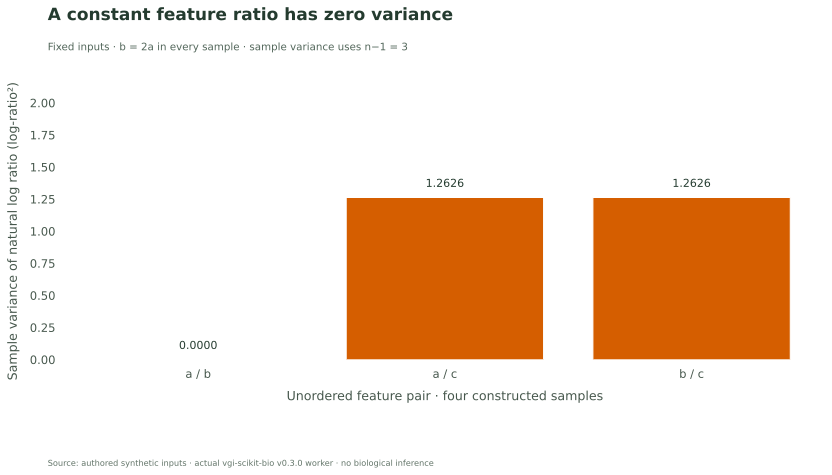

4526

In [13]:
display(checks)
assert checks.passed.all()
prose(
    f"All **{len(checks)} checks** pass, including 36 recovered parts and every VLR entry. The a/b log-ratio variance is **{variances.iloc[0].vlr:.6f}**. The two ratios involving c have positive variance even though changing the ALR reference cannot change this feature-pair result."
)
fig, ax = plt.subplots(figsize=(12, 7))
labels = variances.feature_1 + " / " + variances.feature_2
bars = ax.bar(labels, variances.vlr, color=["#0072B2", "#D55E00", "#D55E00"])
ax.bar_label(bars, fmt="%.4f", padding=8)
ax.set_ylim(0, 2)
ax.set_ylabel("Sample variance of natural log ratio (log-ratio²)")
ax.set_xlabel("Unordered feature pair · four constructed samples")
ax.grid(axis="x", visible=False)
finish(
    fig,
    "A constant feature ratio has zero variance",
    "Fixed inputs · b = 2a in every sample · sample variance uses n−1 = 3",
    SOURCE,
    name="feature-logratio-variance",
)
Path("artifacts/analysis-04.json").write_text(
    json.dumps(
        {
            "reference": REFERENCE_FEATURE,
            "coordinates": coords.to_dict("records"),
            "variances": variances.to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
    )
)

### Experiment: change the ALR reference from a to c

Change `REFERENCE_FEATURE` to **"c"**. Only ALR coordinate values and labels should change. CLR, ILR, the recovered proportions and the feature-variance chart must remain fixed. The three inverse paths still recover the same composition; none recovers the original scale without separately retained totals.

Zeros require an explicitly justified treatment before these log-ratio transforms. This notebook avoids that separate modeling choice by using positive inputs throughout.

In [14]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-scikit-bio](https://github.com/Query-farm/vgi-scikit-bio)
